In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

df = pd.read_excel(
    "Trend Data Combined.ods",
    engine="odf"
)

In [2]:
df["status"] = df["status"].astype(str).str.strip().str.lower()

print(df["status"].value_counts())

y = df["status"].map({
    "healthy": 0,
    "injured": 1
})

status
healthy    28
injured     5
Name: count, dtype: int64


In [3]:
health_features = [
    "resting_heart_rate",
    "stress",
    "nightly_hrv",
    "weekly_hrv",
    "sleep_duration",
    "sleep_score",
    "deep_sleep",
    "light_sleep",
    "rem_sleep",
    "awake_duration",
    "hrv_deviation",
    "hr_drift"
]

running_features = [
    "run_count",
    "distance",
    "elapsed_time",
    "weekly_mileage_change_pct",
    "ground_contact_time",
    "cadence",
    "running_heart_rate",
    "elapsed_pace",
    "stride_length",
    "effort_index",
    "chronic_load",
    "max_streak",
    "max_mileage_increase",
    "avg_mileage_change"
]

In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        zero_division=0
    )
}

In [9]:
def run_adaboost(X, y, category_name):

    base_tree = DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    )

    model = AdaBoostClassifier(
        estimator=base_tree,
        n_estimators=50,
        learning_rate=0.5,
        random_state=42
    )

    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring
    )

    print(f"\n{category_name} - AdaBoost")
    print("-" * 40)

    for metric in scoring:
        scores = results["test_" + metric]

        print(
            f"{metric}: "
            f"{scores.mean():.3f} +/- {scores.std():.3f}"
        )

    y_pred = cross_val_predict(
        model,
        X,
        y,
        cv=cv
    )

    cm = confusion_matrix(
        y,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Healthy", "Injured"]
    )

    disp.plot()

    plt.title(
        f"AdaBoost - {category_name}"
    )

    plt.show()

    print(
        classification_report(
            y,
            y_pred,
            labels=[0, 1],
            target_names=["Healthy", "Injured"],
            zero_division=0
        )
    )

    return model, results


Health Features - AdaBoost
----------------------------------------
accuracy: 0.671 +/- 0.161
balanced_accuracy: 0.397 +/- 0.097
precision: 0.000 +/- 0.000
recall: 0.000 +/- 0.000
f1: 0.000 +/- 0.000


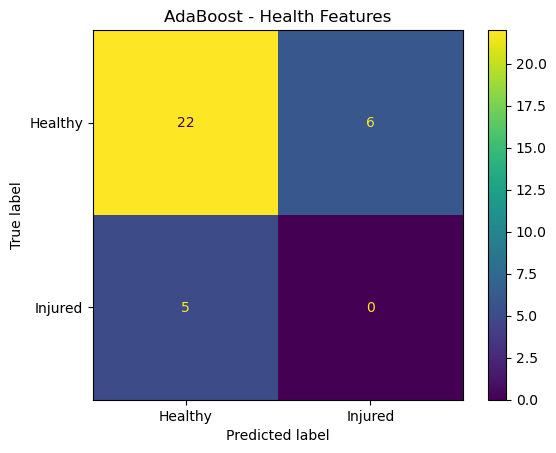

              precision    recall  f1-score   support

     Healthy       0.81      0.79      0.80        28
     Injured       0.00      0.00      0.00         5

    accuracy                           0.67        33
   macro avg       0.41      0.39      0.40        33
weighted avg       0.69      0.67      0.68        33



In [10]:
X_health = df[health_features]

ada_health, ada_health_results = run_adaboost(
    X_health,
    y,
    "Health Features"
)


Running Features - AdaBoost
----------------------------------------
accuracy: 0.724 +/- 0.127
balanced_accuracy: 0.427 +/- 0.073
precision: 0.000 +/- 0.000
recall: 0.000 +/- 0.000
f1: 0.000 +/- 0.000


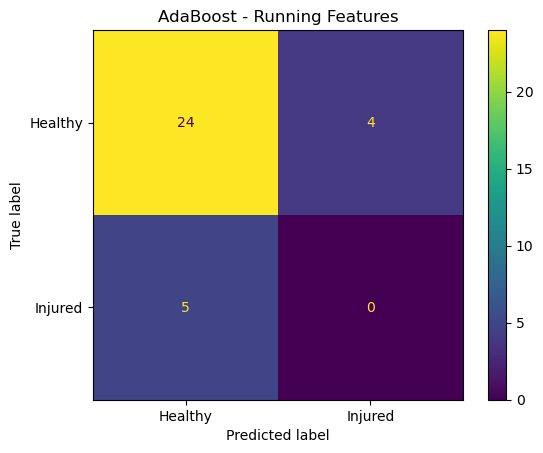

              precision    recall  f1-score   support

     Healthy       0.83      0.86      0.84        28
     Injured       0.00      0.00      0.00         5

    accuracy                           0.73        33
   macro avg       0.41      0.43      0.42        33
weighted avg       0.70      0.73      0.71        33



In [11]:
X_running = df[running_features]

ada_running, ada_running_results = run_adaboost(
    X_running,
    y,
    "Running Features"
)

In [12]:
ada_health.fit(X_health, y)
ada_running.fit(X_running, y)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,
                                                    random_state=42),
                   learning_rate=0.5, random_state=42)

In [13]:
def show_ada_importance(model, features, title):

    importance = pd.DataFrame({
        "Feature": features,
        "Importance": model.feature_importances_
    })

    importance = importance.sort_values(
        "Importance",
        ascending=False
    )

    print(importance)

    top = importance.head(10)

    plt.figure(figsize=(10, 6))

    plt.barh(
        top["Feature"],
        top["Importance"]
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Feature Importance")
    plt.title(title)

    plt.show()

               Feature  Importance
3           weekly_hrv    0.299105
1               stress    0.121268
11            hr_drift    0.103526
2          nightly_hrv    0.102496
8            rem_sleep    0.100136
5          sleep_score    0.060867
6           deep_sleep    0.049226
0   resting_heart_rate    0.049192
10       hrv_deviation    0.045100
7          light_sleep    0.044050
9       awake_duration    0.025033
4       sleep_duration    0.000000


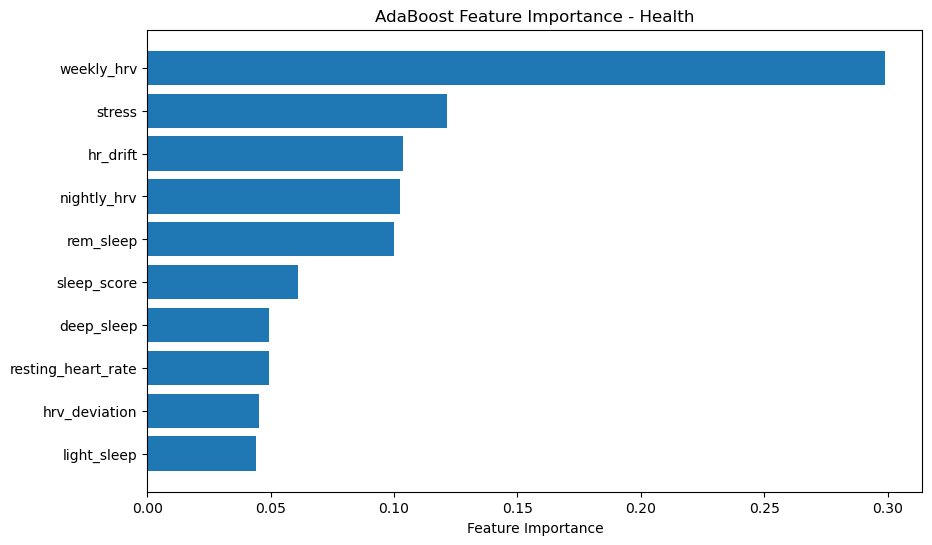

                      Feature  Importance
0                   run_count    0.252280
4         ground_contact_time    0.144351
3   weekly_mileage_change_pct    0.139995
7                elapsed_pace    0.081531
2                elapsed_time    0.081278
5                     cadence    0.071999
9                effort_index    0.064138
6          running_heart_rate    0.060202
10               chronic_load    0.046347
1                    distance    0.043172
11                 max_streak    0.014705
8               stride_length    0.000000
12       max_mileage_increase    0.000000
13         avg_mileage_change    0.000000


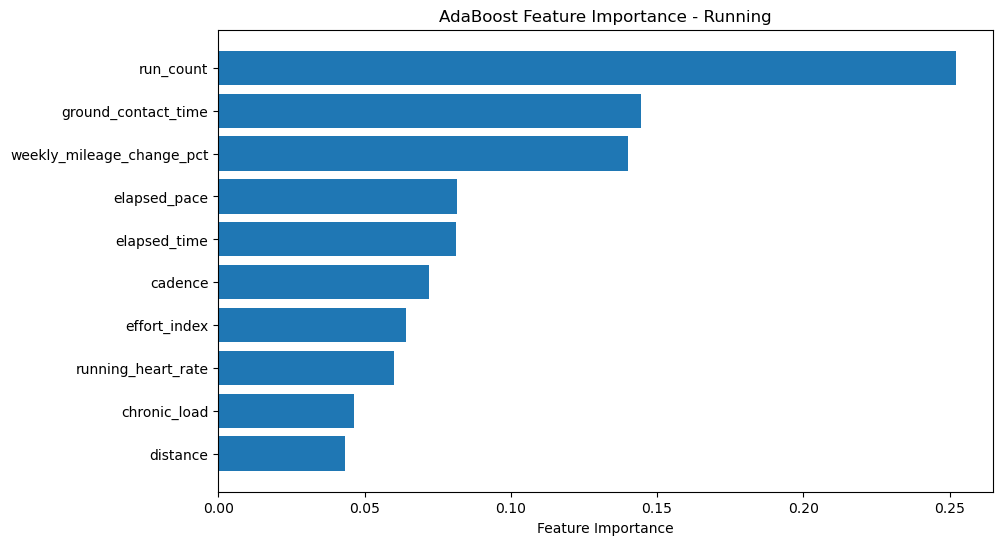

In [14]:
show_ada_importance(
    ada_health,
    health_features,
    "AdaBoost Feature Importance - Health"
)

show_ada_importance(
    ada_running,
    running_features,
    "AdaBoost Feature Importance - Running"
)